# Best model — Random Forest + SMOTE; threshold 0,70

Execução do modelo escolhido no **TEST**, classe positiva **fraude (Class=1)**. F1 é a métrica principal, com Recall, Precision e AP/AUPRC.

A receita de metricas_smotec usa 160 árvores, profundidade 14, mínimo de 2 amostras por folha, 14 features, imputação e StandardScaler. SMOTE só atua no treino. O pacote reutiliza o ajuste existente no TRAIN completo, sem refit.

**Proveniência:** os 89,19% de Precision e 75% de Recall da escolha pertencem à última validação TRAIN. Este TEST já foi consultado em rodadas anteriores: esta execução é uma reavaliação, sem independência confirmatória. Não há seleção ou ajuste de threshold neste notebook.

Cálculos: python -m fraud_detection.deployment --evaluate. Executar o notebook apenas lê relatórios, sem repetir treino ou teste.

In [1]:
# Localiza a raiz ao abrir na pasta notebooks ou na raiz do projeto.
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "reports/metrics"
FIGURES = ROOT / "reports/figures"
required = METRICS / "best_model_metrics.json"
if not required.exists():
    raise FileNotFoundError("Execute python -m fraud_detection.deployment --evaluate.")
result = json.loads(required.read_text(encoding="utf-8"))
metadata = json.loads((ROOT / "best_model/metadata.json").read_text(encoding="utf-8"))
manifest = json.loads((ROOT / "reports/experiments/best_model_manifest.json").read_text(encoding="utf-8"))


## Configuração e amostra
O cutoff mantém TEST posterior ao TRAIN e a prevalência original. Threshold fixo 0,70, definido antes desta execução. A API e o MLflow usam o mesmo pacote.

In [2]:
# Parâmetros, tamanho da amostra e hashes rastreiam esta execução.
display(pd.Series({
    "modelo": metadata["model"], "threshold": result["threshold"],
    "transações TEST": result["rows"], "fraudes TEST": result["positives"],
    "legítimas TEST": result["negatives"], "TRAIN": manifest["train_rows"],
    "cutoff Time": manifest["split"]["cutoff_time"],
    "SHA256 do modelo": manifest["artifact_sha256"],
    "executado em": manifest["evaluated_at"],
}, name="Execução"))
display(pd.Series(metadata["parameters"], name="Hiperparâmetros"))
display(pd.Series(metadata["selected_features"], name="Features"))


modelo                         Random Forest + StandardScaler + SMOTE
threshold                                                         0.7
transações TEST                                                 73434
fraudes TEST                                                       97
legítimas TEST                                                  73337
TRAIN                                                          210292
cutoff Time                                                  138233.6
SHA256 do modelo    b8538cee7a45d9cb95051b6b4acc9d027477cc3d07a3ff...
executado em                         2026-10-29T21:22:46.940434-03:00
Name: Execução, dtype: object

bootstrap                    True
ccp_alpha                     0.0
class_weight                 None
criterion                    gini
max_depth                      14
max_features                 sqrt
max_leaf_nodes               None
max_samples                  None
min_impurity_decrease         0.0
min_samples_leaf                2
min_samples_split               2
min_weight_fraction_leaf      0.0
monotonic_cst                None
n_estimators                  160
n_jobs                          2
oob_score                   False
random_state                   42
verbose                         0
warm_start                  False
Name: Hiperparâmetros, dtype: object

0      V1
1      V2
2      V3
3      V4
4      V5
5      V7
6      V9
7     V10
8     V11
9     V12
10    V14
11    V16
12    V17
13    V18
Name: Features, dtype: object

## F1, Recall e Precision no TEST
Precision é a fração dos alertas que era fraude. Recall é a fração das fraudes detectada. F1 é a média harmônica entre ambos. Os rótulos nas barras são percentuais no threshold 0,70.

,f1,recall,precision,average_precision,roc_auc
"TEST — threshold 0,70",0.817073,0.690722,1.0,0.784309,0.973428


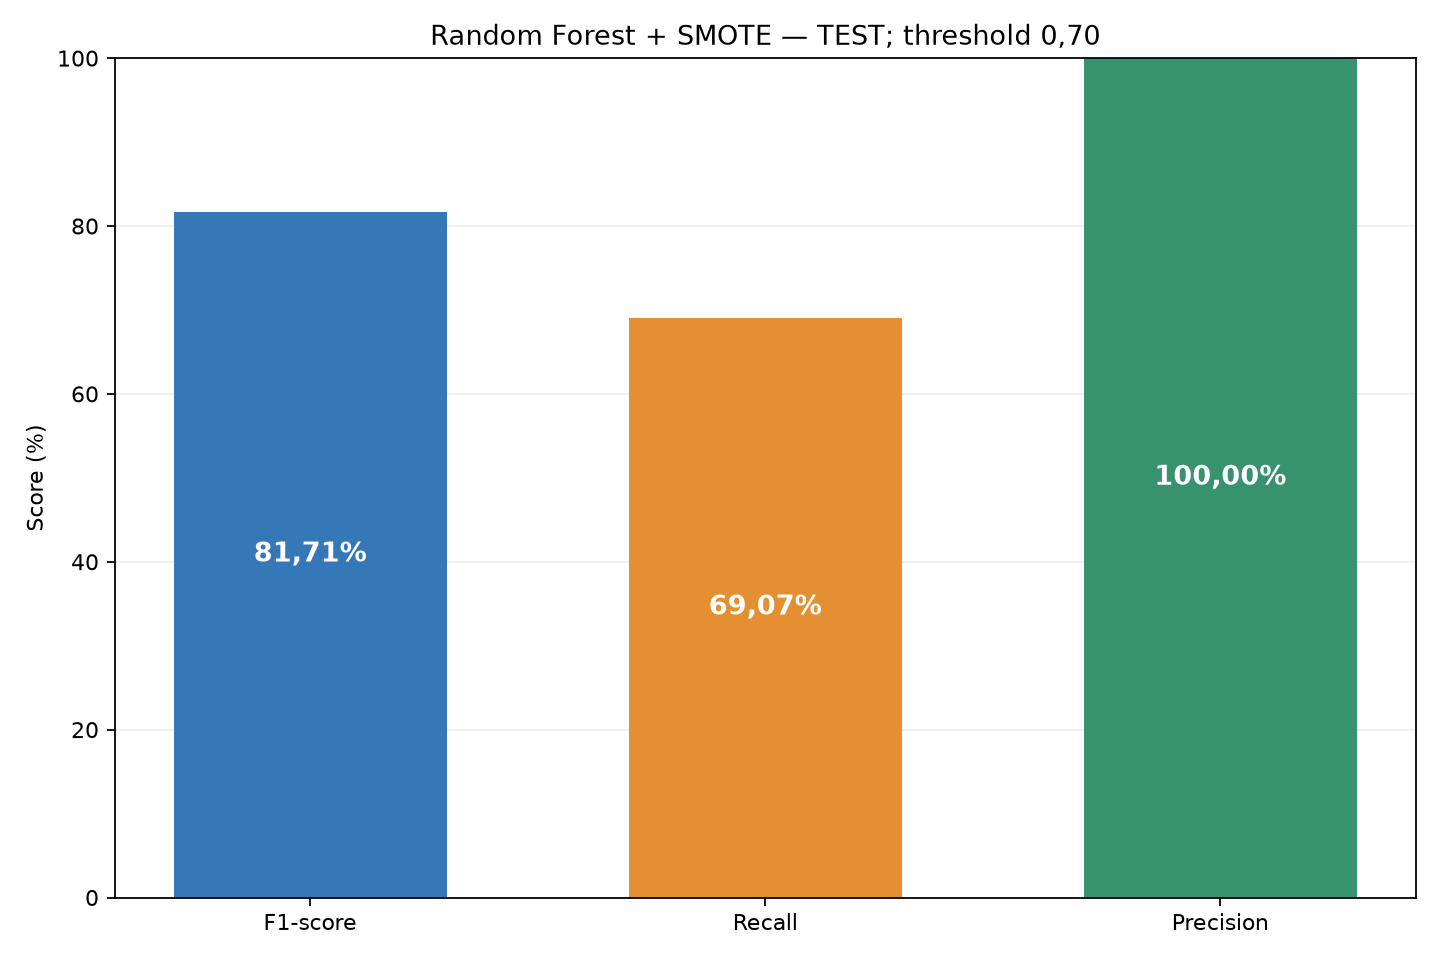

In [3]:
display(pd.DataFrame([{key: result[key] for key in ["f1", "recall", "precision", "average_precision", "roc_auc"]}], index=["TEST — threshold 0,70"]))
display(Image(filename=str(FIGURES / "best_model_f1_recall_precision.png")))


## Todas as métricas e definições
A tabela explica unidade, fórmula e direção desejável. Acurácia isolada pode enganar em classe rara. AP resume Precision ponderada pelos ganhos de Recall; difere da área trapezoidal PR. F2 aparece apenas como complemento ao F1 principal.

In [4]:
# Métricas de decisão, taxas de erro, ordenação e qualidade probabilística.
display(pd.read_csv(METRICS / "best_model_metric_definitions.csv"))


,metric,name,value,unit,definition,preferred
0,precision,Precision,100.000000,%,TP/(TP+FP): fração dos alertas que era fraude,Maior
1,recall,Recall / sensibilidade,69.072165,%,TP/(TP+FN): fração das fraudes detectada,Maior
2,f1,F1,81.707317,%,2PR/(P+R): média harmônica simétrica de Precis...,Maior
3,f2,F2,73.626374,%,5PR/(4P+R): favorece Recall; métrica complemen...,Maior
4,specificity,Especificidade,100.000000,%,TN/(TN+FP): legítimas corretamente liberadas,Maior
5,accuracy,Acurácia,99.959147,%,(TP+TN)/n: acertos totais; pode enganar em cla...,Maior
6,balanced_accuracy,Balanced Accuracy,84.536082,%,(Recall+Especificidade)/2,Maior
7,negative_predictive_value,Valor preditivo negativo,99.959110,%,TN/(TN+FN): legítimas entre não alertadas,Maior
8,false_positive_rate,Taxa de falsos positivos (FPR),0.000000,%,FP/(FP+TN): legítimas alertadas,Menor
9,false_negative_rate,Taxa de falsos negativos (FNR),30.927835,%,FN/(FN+TP): fraudes não detectadas,Menor


## Matriz de confusão e relatório por classe
TP: fraude detectada; FN: fraude liberada; FP: legítima alertada; TN: legítima liberada. A segunda matriz normaliza pela classe real. No relatório, support é a quantidade real por classe; macro pondera classes igualmente e weighted pondera pelo suporte.

,TN,FP,FN,TP
0,73337,0,30,67


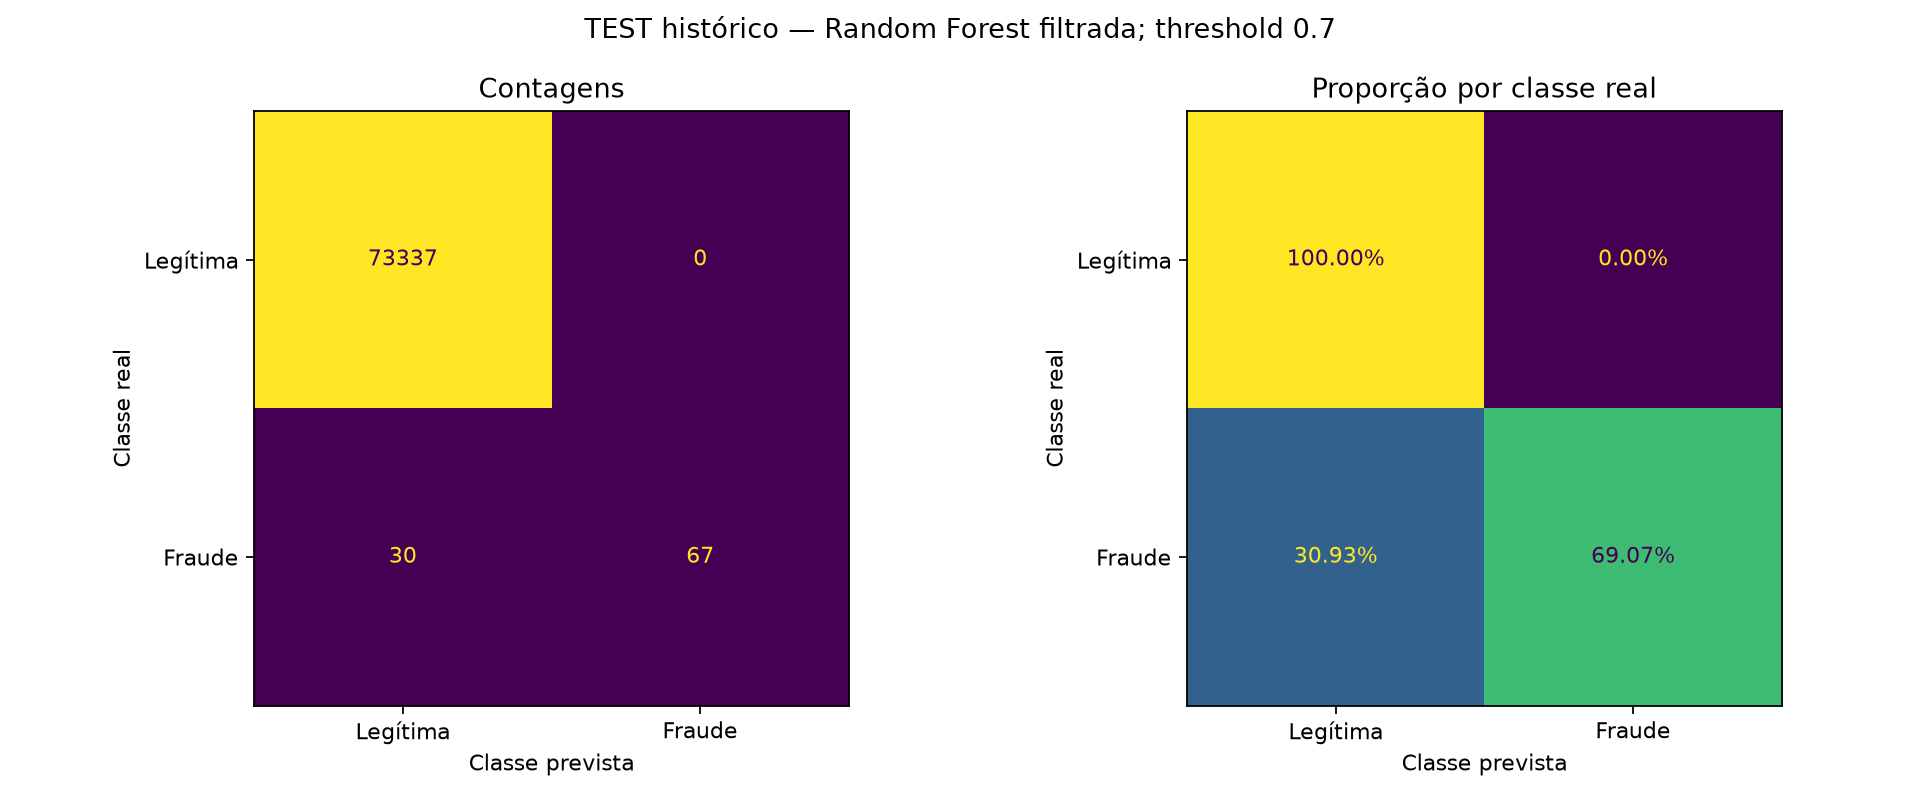

,precision,recall,f1-score,support
Legítima (0),0.999591,1.000000,0.999796,73337.000000
Fraude (1),1.000000,0.690722,0.817073,97.000000
accuracy,0.999591,0.999591,0.999591,0.999591
macro avg,0.999796,0.845361,0.908434,73434.000000
weighted avg,0.999592,0.999591,0.999554,73434.000000


In [5]:
display(pd.DataFrame([{key.upper(): result[key] for key in ["tn", "fp", "fn", "tp"]}]))
display(Image(filename=str(FIGURES / "best_model_confusion.png")))
report = json.loads((METRICS / "best_model_classification_report.json").read_text(encoding="utf-8"))
display(pd.DataFrame(report).T)


## Precision–Recall/AUPRC e ROC
A linha horizontal na PR é a prevalência de fraude. O ponto vermelho corresponde ao threshold fixo 0,70, sem pesquisar limiares no TEST. ROC-AUC complementa AP, mas não substitui Precision e Recall.

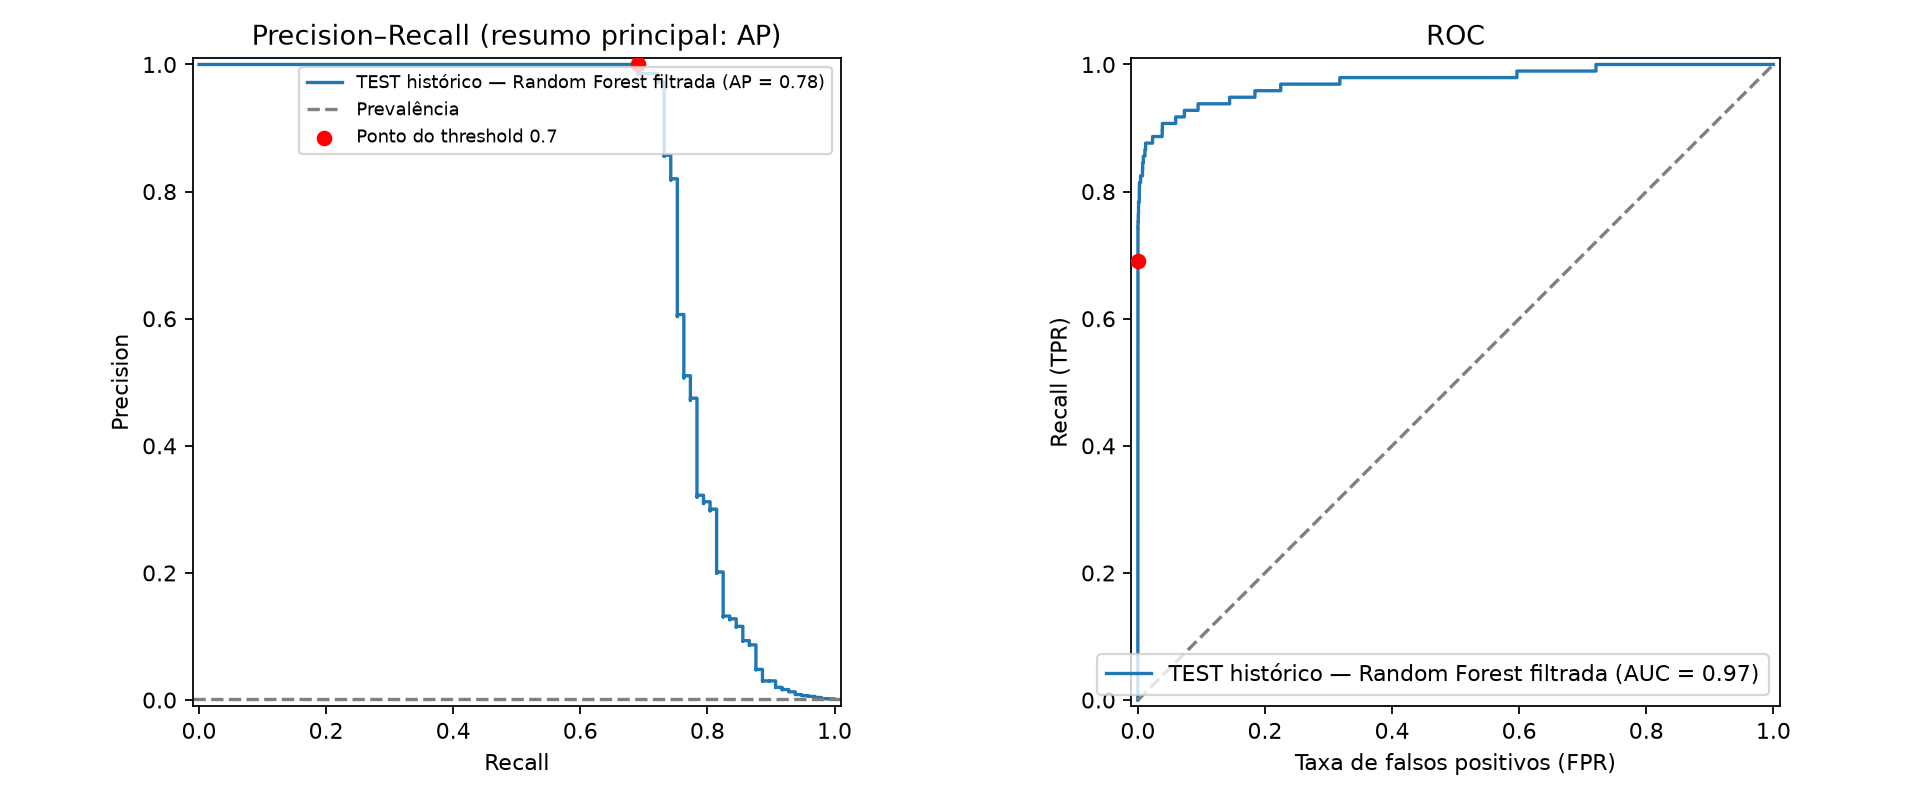

In [6]:
display(Image(filename=str(FIGURES / "best_model_pr_roc.png")))


## Scores e calibração
Log Loss e Brier penalizam scores distantes dos rótulos observados. O diagrama compara score médio por faixa à frequência real. SMOTE altera a distribuição do treino; os scores não têm calibração demonstrada. Nenhum score é recalibrado aqui.

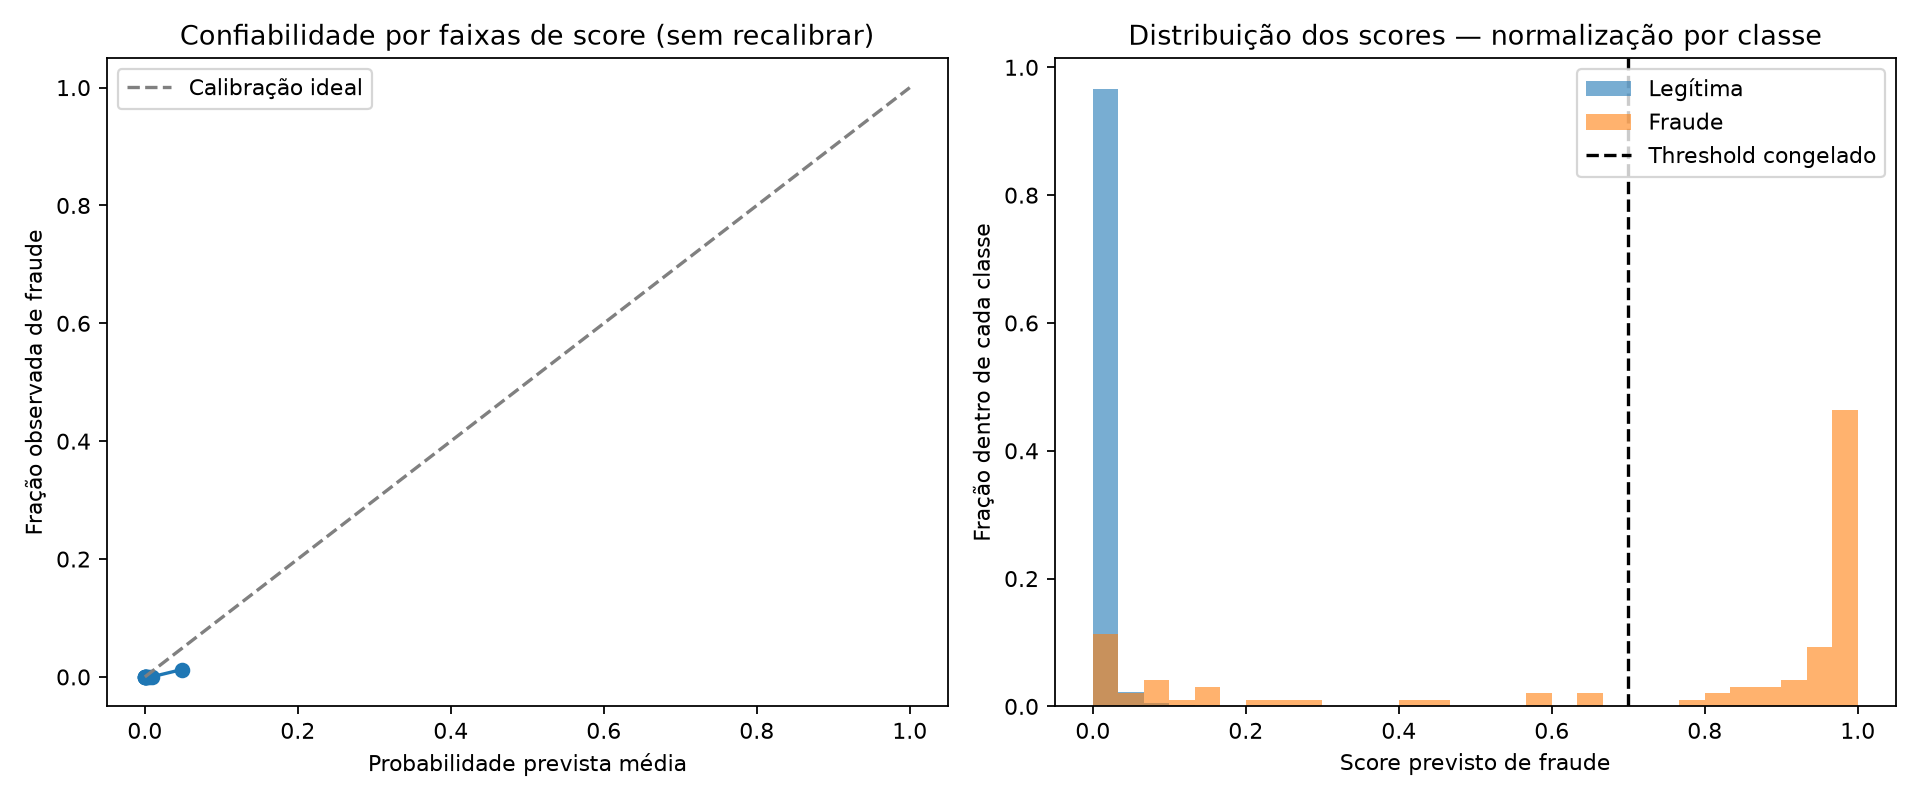

,score_bin,count,fraud_count,predicted_probability,observed_fraud_rate,min_probability,max_probability
0,"(-0.001, 0.000251]",7356,0,0.000161,0.000000,0.000000,0.000251
1,"(0.000251, 0.000403]",7331,0,0.000325,0.000000,0.000251,0.000403
2,"(0.000403, 0.000612]",7343,1,0.000501,0.000136,0.000404,0.000612
3,"(0.000612, 0.000937]",7344,0,0.000763,0.000000,0.000612,0.000937
4,"(0.000937, 0.00145]",7343,1,0.001173,0.000136,0.000937,0.001449
5,"(0.00145, 0.00231]",7343,0,0.001848,0.000000,0.001449,0.002312
6,"(0.00231, 0.00375]",7344,1,0.002958,0.000136,0.002312,0.003750
7,"(0.00375, 0.00645]",7343,1,0.004944,0.000136,0.003751,0.006449
8,"(0.00645, 0.0135]",7343,2,0.009218,0.000272,0.006450,0.013531
9,"(0.0135, 1.0]",7344,91,0.048006,0.012391,0.013537,0.999691


In [7]:
display(Image(filename=str(FIGURES / "best_model_calibration_scores.png")))
display(pd.read_csv(METRICS / "best_model_calibration.csv"))


## Erros por faixas e período
Faixas das features são aprendidas no TRAIN e aplicadas ao TEST. A taxa de fraude descreve fraudes reais na faixa; Recall descreve a parcela detectada; FPR mede legítimas alertadas; FDR mede alertas falsos entre alertas. Denominador vazio produz NaN. Estas análises são descritivas.

In [8]:
# O CSV preserva todas as faixas; a prévia limita apenas a exibição.
segments = pd.read_csv(METRICS / "best_model_feature_segments.csv")
display(segments.head(30))
display(pd.read_csv(METRICS / "best_model_time_segments.csv"))


,fold,feature,bin,count,fraud_count,legitimate_count,tp,fp,fn,tn,fraud_rate_pct,recall_pct,precision_pct,false_positive_rate_pct,missed_fraud_rate_pct,false_alert_share_pct,alert_rate_pct,threshold,source
0,TEST histórico,Time,"(128621.9, inf]",73434,97,73337,67,0,30,73337,0.132091,69.072165,100.0,0.0,30.927835,0.0,0.091238,0.7,TEST histórico reavaliado; bins aprendidos no ...
1,TEST histórico,V1,"(1.907, inf]",23521,3,23518,0,0,3,23518,0.012755,0.000000,NaN,0.0,100.000000,NaN,0.000000,0.7,TEST histórico reavaliado; bins aprendidos no ...
2,TEST histórico,V1,"(1.289, 1.907]",8630,7,8623,1,0,6,8623,0.081112,14.285714,100.0,0.0,85.714286,0.0,0.011587,0.7,TEST histórico reavaliado; bins aprendidos no ...
3,TEST histórico,V1,"(-inf, -1.905]",6792,40,6752,33,0,7,6752,0.588928,82.500000,100.0,0.0,17.500000,0.0,0.485866,0.7,TEST histórico reavaliado; bins aprendidos no ...
4,TEST histórico,V1,"(-0.474, -0.0561]",8347,8,8339,5,0,3,8339,0.095843,62.500000,100.0,0.0,37.500000,0.0,0.059902,0.7,TEST histórico reavaliado; bins aprendidos no ...
5,TEST histórico,V1,"(0.99, 1.173]",339,3,336,3,0,0,336,0.884956,100.000000,100.0,0.0,0.000000,0.0,0.884956,0.7,TEST histórico reavaliado; bins aprendidos no ...
6,TEST histórico,V1,"(-1.162, -0.781]",6039,6,6033,5,0,1,6033,0.099354,83.333333,100.0,0.0,16.666667,0.0,0.082795,0.7,TEST histórico reavaliado; bins aprendidos no ...
7,TEST histórico,V1,"(-0.0561, 0.99]",7532,13,7519,7,0,6,7519,0.172597,53.846154,100.0,0.0,46.153846,0.0,0.092937,0.7,TEST histórico reavaliado; bins aprendidos no ...
8,TEST histórico,V1,"(-1.905, -1.162]",6002,9,5993,6,0,3,5993,0.149950,66.666667,100.0,0.0,33.333333,0.0,0.099967,0.7,TEST histórico reavaliado; bins aprendidos no ...
9,TEST histórico,V1,"(-0.781, -0.474]",5951,6,5945,5,0,1,5945,0.100823,83.333333,100.0,0.0,16.666667,0.0,0.084019,0.7,TEST histórico reavaliado; bins aprendidos no ...


,time_interval,count,fraud_count,tp,fp,fn,tn,recall_pct,precision_pct,false_positive_rate_pct,fraud_rate_pct
0,"(138199.442, 146873.5]",20528,27,19,0,8,20501,70.370370,100.0,0.0,0.131528
1,"(146873.5, 155513.0]",20079,38,27,0,11,20041,71.052632,100.0,0.0,0.189252
2,"(155513.0, 164152.5]",18672,21,16,0,5,18651,76.190476,100.0,0.0,0.112468
3,"(164152.5, 172792.0]",14155,11,5,0,6,14144,45.454545,100.0,0.0,0.077711


## Validação — seção separada do TEST
Folds temporais de TRAIN no threshold 0,70. A escolha ocorreu após inspecionar estes folds: as métricas abaixo não são validação externa à escolha e não são métricas de TEST.

In [9]:
folds = pd.read_csv(METRICS / "model_select_folds.csv")
keys = ["f1", "recall", "precision", "average_precision"]
display(folds[["fold", "source", "threshold", *keys]])
display(folds[keys].agg(["mean", "std"]))


,fold,source,threshold,f1,recall,precision,average_precision
0,1,Validação temporal TRAIN; threshold escolhido ...,0.7,0.740741,0.595238,0.980392,0.775228
1,2,Validação temporal TRAIN; threshold escolhido ...,0.7,0.802083,0.733333,0.885057,0.778772
2,3,Validação temporal TRAIN; threshold escolhido ...,0.7,0.814815,0.750000,0.891892,0.712960


,f1,recall,precision,average_precision
mean,0.785880,0.692857,0.919114,0.755653
std,0.039606,0.084950,0.053178,0.037016


## Interpretação
A avaliação mostra fraudes detectadas, perdidas e falsos alertas. Precision de 100% nesta amostra não garante ausência de falsos alertas futuros. Reduzir threshold tende a aumentar Recall e o volume de alertas; aumentar threshold tende a fazer o oposto. Nenhum ajuste é feito aqui. Há poucas fraudes e apenas dois dias de dados; generalização futura exige dados novos.